# Does tumor clone lineage change expected cell expression and growth? These are tests to see if that direction is worth exploring.

The eTracer dataset let's us test the differences in dynamics betweed a paired coupling flow model and an inferred coupling. I used Claude to generate most of these tests. The notebook assumes familiarity with the etracer_overview and survival_motivation notebooks.

- **Lineage coupling.** Where cells are paired only within their clone (static barcodes, exact). Each clone's mass at Secondary is its observed share of the tumor.
- **Inferred coupling.** This is standard unbalanced entropic OT with no lineage (the UOT-FM default): uniform marginals, a KL penalty on the source side so mass can grow or die.

The following tests measure:

1. **Ancestry.** How much of the inferred coupling's mass stays within clone, and how often it assigns a
   Secondary cell to the right clone, against chance.
2. **Growth.** Per-clone growth implied by each coupling against the same clone's measured growth in the sister tumor (an independent mouse), so the lineage coupling is scored too rather than serving as the answer key.
3. **Dynamics.** State-to-state transition matrices under each coupling.
4. **Velocity targets.** Per-cell agreement of the implied displacements.
5. **Generalisation.** The same one-step linear "flow" (ridge from a cell's position to its displacement), trained on each coupling's targets on training clones, scored on held-out clones' observed Secondary means.

All in 50 PCs of the nuclear gene panel, per founder family and Secondary tumor (six datasets).
Names follow `etracer_overview`. Terms are defined in `GLOSSARY.md`.

## Summary

| # | Test | Found | Hypothesis |
| --- | --- | --- | --- |
| 1 | Ancestry: does inferred OT pair cells within their clone? | Within-clone mass 2–4% vs chance 1–1.6%; correct source clone for 3–12% of Secondary cells, below the 15–47% from always guessing the largest clone. Same at every τ. | Expression proximity carries no lineage. Any lineage-free coupling pairs cells across clones almost at random. |
| 2 | Growth: which coupling's growth is right, judged against the same clone's measured growth in the sister tumor (independent mouse)? | Lineage r = 0.36 (0.23–0.43 by dataset: the between-mouse reproducibility of real growth, so the ceiling); inferred r = 0.12–0.14 at every τ, spread 0.1–0.8 log2 against 2.5 measured; lost clones given growth 0.8–1.0. Freer marginals widen the spread, not the correlation. | Growth is not readable from where cells sit in expression space. Only the barcodes supply it. |
| 3 | Dynamics: state-to-state transition rows | Hypoxic / Proliferative / EMT rows agree within sister-tumor variation (TV 0.03–0.2 vs 0.18–0.21). Metabolic row disagrees (TV 0.48–0.80): lineage keeps 0.68–0.89 of surviving Metabolic mass Metabolic; inferred OT moves 65–90% of it to the other states. | The Metabolic collapse (1,608 → 256/140 cells) is selection: survivors keep their state and the rest die. A lineage-free coupling reads that selection as state change, because mass must go somewhere. |
| 4 | Velocity targets: per-cell displacement | Cosine 0.64–0.80 between couplings; inferred 70–85% as long. ~55% of the lineage displacement is the clone's mean shift, ~45% within-clone redistribution. | The two couplings agree on the mean-field direction and differ on magnitude and on who moves. |
| 5 | Generalisation: identical ridge position → displacement, held-out clones | Observed Secondary clone means predicted at r = 0.44 (lineage), 0.20–0.23 (inferred, any τ), 0.38 (carry-forward). Lineage beats carry-forward 4/6, ties 1; inferred below carry-forward 6/6. | Lineage targets contain learnable clone-level dynamics; inferred targets contain a systematic error (moving selected cells) that shows on unseen clones. |

### Next steps, ranked

| Rank | Step | Why it is next | Decides |
| --- | --- | --- | --- |
| 1 | Train UOT-FM twice. Clone-masked vs inferred coupling, everything else identical; interval as input; ≥3 seeds per fold. | The pre-training comparison predicts the outcome; the trained pair is the contribution. | Whether the trained flows reproduce rows 3 and 5 above. |
| 2 | Score both flows on three things: held-out clone means; per-state growth attribution vs measured clone-fraction change; the Metabolic transition row. | These are the three places the couplings disagree; anything else will look the same. | Which coupling's flow is right, and where the lineage-free one fails. |
| 3 | Repeat on Secondary → Tertiary tumors. | Identity changes less than Primary -> Secondary, so differences between flows say more about growth. | Whether the "selection read as state change" error is specific to the first encounter with T cells. |
| 4 | Down-weight noisy extinctions in the lineage marginals (`etracer-gap-clones`, ~5–10% false extinctions). | Lost clones carry zero mass in the lineage coupling; a few are survivors below detection. | Sensitivity of rows 2 and 5 to label noise. |
| 5 | Vary ε and the within-clone pairing (balanced vs. unbalanced inside a clone). | The lineage coupling is only as right as OT is inside a clone. | Whether within-clone redistribution (the ~45%) is stable. |
| 6 | Condition the field at most on interval and the ridge-predicted clone shift; no learned clone code. | The code memorises (`offset-vs-distribution`); the mean is already at its ceiling (`residual_change`). | Not a test: a design constraint carried from the earlier notebooks. |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
import etracer as et

P = et.Paths(Path.cwd().parent)
REVIEW = P.root / "review" / "adversarial_2026-11-01"
STATE_NAMES = ["Hypoxic", "Proliferative", "EMT", "Metabolic", "Interferon response"]
BLUE, ORANGE, AQUA, INK, MUTED, FAINT = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#c3c2b7"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})

In [2]:
# Cells, expression and a 50-PC space fitted on Primary + Secondary cells (same cache as residual_change).
# GLOSSARY.md: PCs (principal components), log-CPM / log1p(CP10k)
FAMILY_OF = {"a3026": "A", "a3028": "B", "a3030": "C"}
TUMOR_OF = {("BL", "0"): "Primary", ("EE", "1"): "Secondary a", ("EE", "2"): "Secondary b"}
meta = et.load_metadata(P).reset_index(drop=True)
meta["family"] = meta.family.map(FAMILY_OF)
meta["tumor"] = [TUMOR_OF.get(k) for k in zip(meta.stage, meta.branch.astype(str))]

early = np.load(P.derived / "flow_v1_cells.npz", allow_pickle=True)
nuclear = ~pd.Series(early["genes_panel"]).str.startswith("mt-").to_numpy()
L = early["Lc"][:, nuclear].astype(np.float32)
row_of = pd.Series(np.arange(len(L)), index=meta.cell.to_numpy()[early["need_idx"]])
del early

cells = meta[meta.called & meta.tumor.notna() & meta.cell.isin(row_of.index)].copy()
cells["row"] = row_of[cells.cell].to_numpy()
cells["state_name"] = cells.state.map(dict(zip(et.STATES, STATE_NAMES)))

# PCA by eigen-decomposition of the gene covariance (2,371 x 2,371), fitted on the cells used here.
Xc = L[cells.row.to_numpy()].astype(np.float64)
mu = Xc.mean(0); Xc -= mu
C = Xc.T @ Xc / len(Xc)
w, V = np.linalg.eigh(C)
V = V[:, ::-1][:, :50]
Z = Xc @ V
cells["z"] = list(range(len(cells)))          # row index into Z
print(f"{len(cells):,} Primary + Secondary cells; 50 PCs carry {w[::-1][:50].sum() / w.sum():.0%} of panel variance")
del Xc, C

28,851 Primary + Secondary cells; 50 PCs carry 39% of panel variance


## Couplings

Cost is squared Euclidean distance in PC space, divided by its median so $\varepsilon$ means the same thing
in every dataset. $\varepsilon = 0.1$. The inferred coupling relaxes the **source** marginal with a KL penalty
of weight $\tau$ (mass may grow or vanish) and keeps the target marginal fixed; three values of $\tau$ are run, from nearly
free growth ($\tau = 0.02$, exponent $\tau/(\tau+\varepsilon) = 0.17$) to nearly balanced ($\tau = 1$, exponent 0.91),
because growth is the thing lineage supplies and the inferred coupling has to guess it.

In [3]:
# GLOSSARY.md: unbalanced OT coupling, flow matching
EPS = 0.1


def sqdist(A, B):
    d = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.maximum(d, 0)


def sinkhorn(K, a, b, tau=None, iters=500, tol=1e-7):
    # Scaling iterations. tau=None: balanced. Otherwise KL(source marginal || a) with weight tau; target fixed.
    u, v = np.ones_like(a), np.ones_like(b)
    p = 1.0 if tau is None else tau / (tau + EPS)
    for it in range(iters):
        Kv = K @ v
        u_new = (a / np.maximum(Kv, 1e-300)) ** p
        v_new = b / np.maximum(K.T @ u_new, 1e-300)
        if np.abs(u_new - u).max() < tol and np.abs(v_new - v).max() < tol:
            u, v = u_new, v_new; break
        u, v = u_new, v_new
    return u, v


def coupling_summaries(Z0, Z1, s0, s1, u, v, K, clone0=None):
    # Everything we need from pi = diag(u) K diag(v) without storing it twice.
    Kv = K @ v
    row = u * Kv                                   # source marginal
    disp = (u[:, None] * (K @ (v[:, None] * Z1))) / np.maximum(row[:, None], 1e-300) - Z0
    T = np.zeros((5, 5))                           # state transitions: mass from source state i to target state j
    for i in range(5):
        ui = np.where(s0 == i, u, 0.0)
        colmass = v * (K.T @ ui)
        for j in range(5):
            T[i, j] = colmass[s1 == j].sum()
    return dict(row=row, disp=disp, T=T)

In [4]:
DATASETS = [(f, t) for f in "ABC" for t in ("Secondary a", "Secondary b")]
TAUS = (0.02, 0.1, 1.0)   # relaxation exponent tau/(tau+eps): 0.17, 0.5, 0.91
RES = {}
for family, tumor in DATASETS:
    d0 = cells[(cells.family == family) & (cells.tumor == "Primary")].reset_index(drop=True)
    d1 = cells[(cells.family == family) & (cells.tumor == tumor)].reset_index(drop=True)
    Z0, Z1 = Z[d0.z.to_numpy()], Z[d1.z.to_numpy()]
    s0, s1 = d0.state.to_numpy().astype(int) - 1, d1.state.to_numpy().astype(int) - 1
    Cm = sqdist(Z0, Z1); Cm /= np.median(Cm)
    K = np.exp(-Cm / EPS)
    a, b = np.full(len(Z0), 1 / len(Z0)), np.full(len(Z1), 1 / len(Z1))
    out = {"n0": len(Z0), "n1": len(Z1), "clone0": d0.clone.to_numpy(), "clone1": d1.clone.to_numpy(),
           "s0": s0, "s1": s1, "Z0": Z0, "Z1": Z1}

    # Inferred: unbalanced on the source, two tau values.
    for tau in TAUS:
        u, v = sinkhorn(K, a, b, tau=tau)
        summ = coupling_summaries(Z0, Z1, s0, s1, u, v, K)
        # Mass each target cell receives from each source clone: for clone assignment.
        clones0 = pd.Index(sorted(set(d0.clone)))
        M = np.zeros((len(clones0), len(d0))); M[clones0.get_indexer(d0.clone), np.arange(len(d0))] = 1
        summ["clone_mass"] = (M * u[None, :]) @ K * v[None, :]       # clones x targets
        summ["clones0"] = clones0
        out[f"inferred τ={tau:g}"] = summ

    # Lineage: block-diagonal within clone, balanced inside each block, block mass = clone's Secondary share.
    row = np.zeros(len(Z0)); disp = np.full(Z0.shape, np.nan); T = np.zeros((5, 5))
    shared = sorted(set(d0.clone) & set(d1.clone))
    for c in shared:
        i0, i1 = np.where(d0.clone.to_numpy() == c)[0], np.where(d1.clone.to_numpy() == c)[0]
        Kb = K[np.ix_(i0, i1)]
        if Kb.max() < 1e-290:                       # far-apart block: widen epsilon locally
            Kb = np.exp(-Cm[np.ix_(i0, i1)] / (EPS * 10))
        ub, vb = sinkhorn(Kb, np.full(len(i0), 1 / len(i0)), np.full(len(i1), 1 / len(i1)))
        mass = len(i1) / len(Z1)
        sb = coupling_summaries(Z0[i0], Z1[i1], s0[i0], s1[i1], ub * mass, vb, Kb)
        row[i0], disp[i0], T = sb["row"], sb["disp"], T + sb["T"]
    out["lineage"] = dict(row=row, disp=disp, T=T, shared=shared)
    RES[family, tumor] = out
    print(f"{family} Primary -> {tumor}: {len(Z0)} x {len(Z1)} cells, {len(shared)} shared clones, "
          f"{np.isin(d0.clone, shared).mean():.0%} of Primary cells have descendants")

A Primary -> Secondary a: 4985 x 3248 cells, 49 shared clones, 46% of Primary cells have descendants
A Primary -> Secondary b: 4985 x 1203 cells, 45 shared clones, 49% of Primary cells have descendants
B Primary -> Secondary a: 5784 x 2915 cells, 69 shared clones, 64% of Primary cells have descendants
B Primary -> Secondary b: 5784 x 3166 cells, 69 shared clones, 64% of Primary cells have descendants
C Primary -> Secondary a: 5572 x 1195 cells, 43 shared clones, 47% of Primary cells have descendants
C Primary -> Secondary b: 5572 x 783 cells, 39 shared clones, 32% of Primary cells have descendants


## 1. Ancestry: does inferred OT recover the clone pairing?

For every Secondary cell, the inferred coupling spreads its mass over Primary cells. Two readings: the share
of all transported mass that stays within the true clone (chance: $\sum_k p_k q_k$ over clone shares), and
the share of Secondary cells whose largest-mass source clone is their own (chance: always guess the largest
clone). The lineage coupling scores 1.00 on both by construction; it is listed so each row reads as a pair.

In [5]:
rows = []
for (family, tumor), out in RES.items():
    p = pd.Series(out["clone0"]).value_counts(normalize=True)
    q = pd.Series(out["clone1"]).value_counts(normalize=True)
    chance_mass = sum(p.get(c, 0) * q.get(c, 0) for c in set(p.index) | set(q.index))
    chance_top1 = q.max()
    for tau in TAUS:
        s = out[f"inferred τ={tau:g}"]
        cm = s["clone_mass"]
        truth = s["clones0"].get_indexer(out["clone1"])          # -1 where the target clone has no Primary cells
        ok = truth >= 0
        within = cm[truth[ok], np.where(ok)[0]].sum() / cm[:, ok].sum()
        top1 = (cm[:, ok].argmax(0) == truth[ok]).mean()
        rows.append(dict(dataset=f"{family} → {tumor}", tau=tau, within_clone_mass_inferred=within, within_clone_mass_lineage=1.0,
                         chance_mass=chance_mass, top1_clone_inferred=top1, top1_clone_lineage=1.0, chance_top1=chance_top1))
ancestry = pd.DataFrame(rows)
ancestry.round(3)

            dataset   tau  within_clone_mass_inferred  within_clone_mass_lineage  chance_mass  top1_clone_inferred  top1_clone_lineage  chance_top1
0   A → Secondary a  0.02                       0.030                        1.0        0.010                0.045                 1.0        0.246
1   A → Secondary a  0.10                       0.029                        1.0        0.010                0.037                 1.0        0.246
2   A → Secondary a  1.00                       0.026                        1.0        0.010                0.030                 1.0        0.246
3   A → Secondary b  0.02                       0.031                        1.0        0.012                0.031                 1.0        0.151
4   A → Secondary b  0.10                       0.030                        1.0        0.012                0.029                 1.0        0.151
5   A → Secondary b  1.00                       0.026                        1.0        0.012                0.0

## 2. Growth: which coupling's growth is right?

The source marginal of a coupling, divided by the uniform source weight, is each Primary cell's implied
growth; averaged over a clone's cells it is the clone's implied growth. For the lineage coupling that is the
measured clone-fraction change in *this* tumor, so comparing it with the same measurement would be circular.
The fair test uses an independent measurement: the same clone's measured growth in the **sister** Secondary
tumor, a different mouse engrafted from the same Primary tumor. Both couplings are scored on the same clones
(≥ 5 Primary cells, present in both Secondary tumors), on log scale. The lineage column is therefore the
reproducibility of real clone growth between mice — the ceiling an inferred coupling could reach.

In [6]:
SISTER = {"Secondary a": "Secondary b", "Secondary b": "Secondary a"}
rows, GROWTH = [], {}
for (family, tumor), out in RES.items():
    other = RES[family, SISTER[tumor]]
    d0 = pd.DataFrame({"clone": out["clone0"]})
    n_prim = d0.clone.value_counts()
    g_here = d0.assign(g=out["lineage"]["row"] * out["n0"]).groupby("clone").g.mean()          # lineage, this tumor
    g_sister = d0.assign(g=other["lineage"]["row"] * other["n0"]).groupby("clone").g.mean()    # measured, sister tumor
    both = (g_here > 0) & (g_sister > 0) & (n_prim.reindex(g_here.index) >= 5)
    lg_s = np.log2(g_sister[both])
    lg_l = np.log2(g_here[both])
    row = dict(dataset=f"{family} → {tumor}", clones=int(both.sum()),
               lineage_r=et.pearson(lg_s, lg_l), lineage_spearman=et.spearman(lg_s, lg_l), sd_measured_log2=lg_s.std(),
               sd_lineage_log2=lg_l.std())
    GROWTH[family, tumor, "lineage"] = (lg_s, lg_l)
    lost_here = g_here == 0
    for tau in TAUS:
        g_inf = d0.assign(g=out[f"inferred τ={tau:g}"]["row"] * out["n0"]).groupby("clone").g.mean()
        lg_i = np.log2(g_inf[both])
        row[f"inferred_r τ={tau:g}"] = et.pearson(lg_s, lg_i)
        row[f"sd_inferred_log2 τ={tau:g}"] = lg_i.std()
        row[f"lost_clones_growth τ={tau:g}"] = g_inf[lost_here].median()
        GROWTH[family, tumor, tau] = (lg_s, lg_i)
    rows.append(row)
growth = pd.DataFrame(rows).set_index("dataset")
growth.loc["mean"] = growth.mean()
cols = ["clones", "lineage_r"] + [f"inferred_r τ={t:g}" for t in TAUS] + ["sd_measured_log2", "sd_lineage_log2"] + \
       [f"sd_inferred_log2 τ={t:g}" for t in TAUS] + [f"lost_clones_growth τ={t:g}" for t in TAUS]
growth[cols].round(2)

                 clones  lineage_r  inferred_r τ=0.02  inferred_r τ=0.1  inferred_r τ=1  sd_measured_log2  sd_lineage_log2  sd_inferred_log2 τ=0.02  sd_inferred_log2 τ=0.1  sd_inferred_log2 τ=1  lost_clones_growth τ=0.02  lost_clones_growth τ=0.1  lost_clones_growth τ=1
dataset                                                                                                                                                                                                                                                                       
A → Secondary a   35.00       0.43               0.16              0.19            0.24              2.59             2.88                     0.51                    0.39                  0.13                       0.76                      0.83                    0.93
A → Secondary b   35.00       0.43               0.10              0.10            0.09              2.88             2.59                     0.74                    0.59                

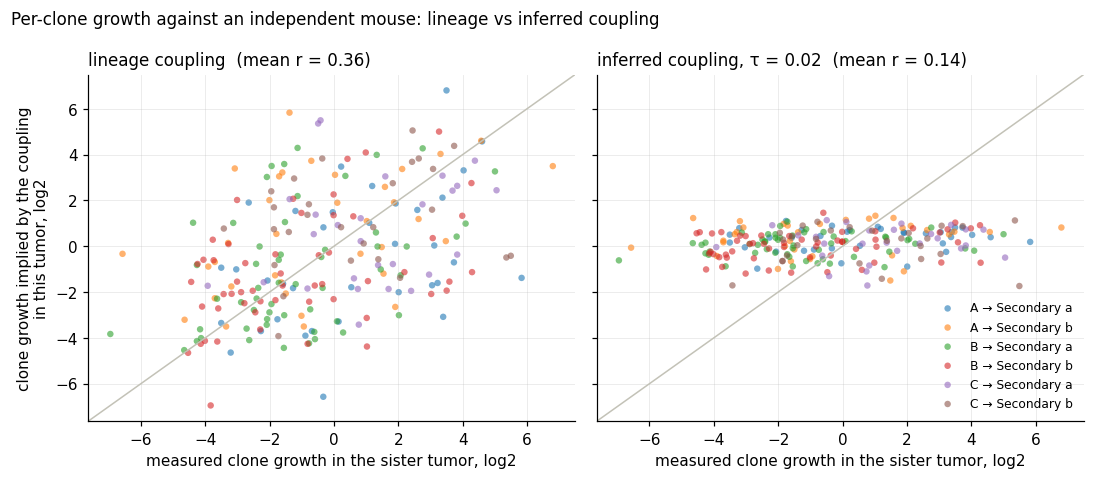

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
for ax, key, title in zip(axs, ("lineage", TAUS[0]), ("lineage coupling", f"inferred coupling, τ = {TAUS[0]:g}")):
    for (family, tumor) in DATASETS:
        lg_s, lg_c = GROWTH[family, tumor, key]
        ax.scatter(lg_s, lg_c, s=18, alpha=0.6, edgecolor="none", label=f"{family} → {tumor}")
    ax.axline((0, 0), slope=1, color=FAINT, lw=1)
    r = growth.loc["mean", "lineage_r" if key == "lineage" else f"inferred_r τ={key:g}"]
    ax.set_title(f"{title}  (mean r = {r:.2f})", loc="left")
    ax.set_xlabel("measured clone growth in the sister tumor, log2")
axs[0].set_ylabel("clone growth implied by the coupling\nin this tumor, log2")
axs[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Per-clone growth against an independent mouse: lineage vs inferred coupling", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

## 3. Dynamics: state-to-state transitions

$T_{ij}$ is the share of transported mass from Primary state $i$ to Secondary state $j$, normalised by row
so each row is "where does state $i$ go". The lineage coupling's rows are the real within-clone redistribution
(given the clone pairing); the inferred coupling's are what a lineage-free flow would learn.

In [8]:
def row_norm(T):
    return T / np.maximum(T.sum(1, keepdims=True), 1e-12)


rows, TMATS = [], {}
for (family, tumor), out in RES.items():
    TL = row_norm(out["lineage"]["T"]); TMATS[family, tumor, "lineage"] = TL
    for tau in TAUS:
        TI = row_norm(out[f"inferred τ={tau:g}"]["T"]); TMATS[family, tumor, tau] = TI
        tv = 0.5 * np.abs(TL - TI).sum(1)                   # total variation per source state
        rows.append(dict(dataset=f"{family} → {tumor}", tau=tau, **{f"TV_{n.split()[0]}": v for n, v in zip(STATE_NAMES, tv)},
                         TV_mean=tv.mean()))
transitions = pd.DataFrame(rows)
# Reference: how different are the two Secondary tumors of the same family under the lineage coupling?
ref = []
for family in "ABC":
    tv = 0.5 * np.abs(TMATS[family, "Secondary a", "lineage"] - TMATS[family, "Secondary b", "lineage"]).sum(1)
    ref.append(dict(family=family, TV_mean_between_sister_tumors_lineage=tv.mean()))
print("Reference: lineage transitions, Secondary a vs b of the same family (biological + sampling variation)")
print(pd.DataFrame(ref).round(3).to_string(index=False))
transitions.round(3)

Reference: lineage transitions, Secondary a vs b of the same family (biological + sampling variation)
family  TV_mean_between_sister_tumors_lineage
     A                                  0.209
     B                                  0.191
     C                                  0.182


            dataset   tau  TV_Hypoxic  TV_Proliferative  TV_EMT  TV_Metabolic  TV_Interferon  TV_mean
0   A → Secondary a  0.02       0.231             0.137   0.095         0.632          0.500    0.319
1   A → Secondary a  0.10       0.192             0.140   0.106         0.651          0.500    0.318
2   A → Secondary a  1.00       0.080             0.172   0.103         0.683          0.500    0.308
3   A → Secondary b  0.02       0.318             0.035   0.156         0.540          0.293    0.268
4   A → Secondary b  0.10       0.252             0.037   0.134         0.567          0.296    0.257
5   A → Secondary b  1.00       0.077             0.086   0.038         0.624          0.307    0.226
6   B → Secondary a  0.02       0.054             0.117   0.038         0.479          0.287    0.195
7   B → Secondary a  0.10       0.045             0.092   0.054         0.493          0.321    0.201
8   B → Secondary a  1.00       0.045             0.046   0.092         0.511     

In [9]:
# The rows that disagree: where do Metabolic and Interferon-response Primary cells go under each coupling?
short = [n.split()[0] for n in STATE_NAMES]
rows = []
for (family, tumor) in DATASETS:
    for key, label in (("lineage", "lineage"), (TAUS[0], f"inferred τ={TAUS[0]:g}")):
        T = TMATS[family, tumor, key]
        for i in (3, 4):
            rows.append(dict(dataset=f"{family} → {tumor}", coupling=label, source=short[i],
                             **{f"→ {s}": T[i, j] for j, s in enumerate(short)}))
sizes = cells.groupby(["tumor", "state_name"]).size().unstack().reindex(columns=STATE_NAMES)
print("cells per state:\n" + sizes.to_string())
pd.DataFrame(rows).set_index(["dataset", "source", "coupling"]).round(2)

cells per state:
state_name   Hypoxic  Proliferative   EMT  Metabolic  Interferon response
tumor                                                                    
Primary         5113           5877  3672       1608                   71
Secondary a     1479           2363  2598        256                  662
Secondary b      816           1633  2317        140                  246


                                            → Hypoxic  → Proliferative  → EMT  → Metabolic  → Interferon
dataset         source     coupling                                                                     
A → Secondary a Metabolic  lineage               0.01             0.04   0.03         0.88          0.04
                Interferon lineage               0.00             0.00   0.00         0.00          0.00
                Metabolic  inferred τ=0.02       0.21             0.20   0.25         0.25          0.09
                Interferon inferred τ=0.02       0.05             0.18   0.30         0.09          0.38
A → Secondary b Metabolic  lineage               0.02             0.05   0.01         0.89          0.03
                Interferon lineage               0.00             0.39   0.17         0.35          0.08
                Metabolic  inferred τ=0.02       0.10             0.24   0.24         0.35          0.07
                Interferon inferred τ=0.02       0.03  

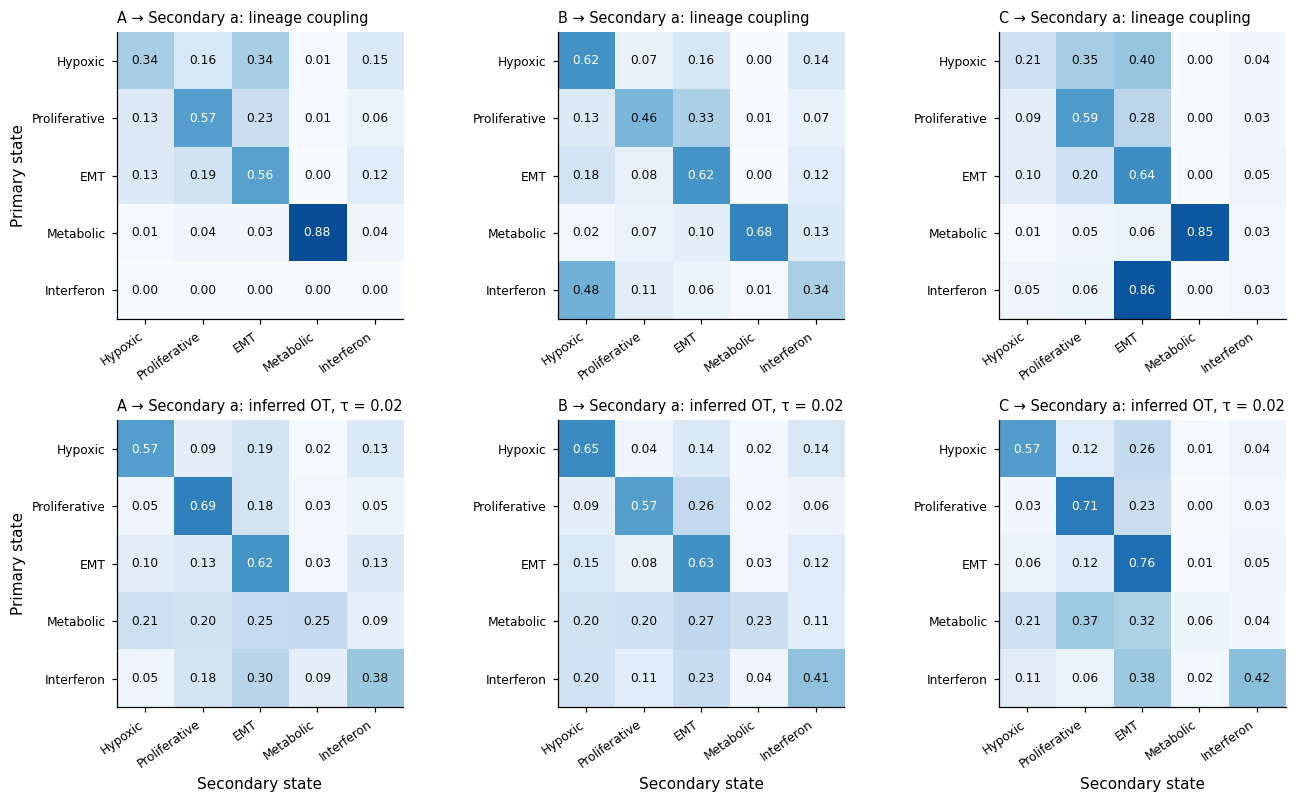

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(12.5, 7.4))
show = [("A", "Secondary a"), ("B", "Secondary a"), ("C", "Secondary a")]
short = [n.split()[0] for n in STATE_NAMES]
for col, (family, tumor) in enumerate(show):
    for r, key, title in ((0, "lineage", "lineage coupling"), (1, TAUS[0], f"inferred OT, τ = {TAUS[0]:g}")):
        ax = axs[r, col]; T = TMATS[family, tumor, key]
        ax.imshow(T, cmap="Blues", vmin=0, vmax=1)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f"{T[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if T[i, j] > 0.55 else INK)
        ax.set_xticks(range(5)); ax.set_xticklabels(short, rotation=35, ha="right", fontsize=8)
        ax.set_yticks(range(5)); ax.set_yticklabels(short, fontsize=8); ax.grid(False)
        ax.set_title(f"{family} → {tumor}: {title}", loc="left", fontsize=9.5)
axs[0, 0].set_ylabel("Primary state"); axs[1, 0].set_ylabel("Primary state")
for ax in axs[1]: ax.set_xlabel("Secondary state")
plt.tight_layout(); plt.show()

## 4. Velocity targets

The flow-matching regression target for a Primary cell is its expected displacement under the coupling,
$\mathbb{E}_\pi[x_1 \mid x_0] - x_0$. Per cell (clones present at both ends): cosine between the lineage and
inferred displacement, and the ratio of their lengths. Also how much of the lineage displacement is the
clone's mean shift versus cell-specific.

In [11]:
rows = []
for (family, tumor), out in RES.items():
    dl = out["lineage"]["disp"]; ok = np.isfinite(dl[:, 0])
    clone = pd.Series(out["clone0"][ok])
    dl_ok = dl[ok]
    clone_mean = pd.DataFrame(dl_ok).groupby(clone.to_numpy()).transform("mean").to_numpy()
    clone_share = (clone_mean ** 2).sum() / (dl_ok ** 2).sum()
    for tau in TAUS:
        di = out[f"inferred τ={tau:g}"]["disp"][ok]
        cos = (dl_ok * di).sum(1) / np.maximum(np.linalg.norm(dl_ok, axis=1) * np.linalg.norm(di, axis=1), 1e-12)
        # Agreement at clone level: cosine between clone-mean displacements.
        ci = pd.DataFrame(di).groupby(clone.to_numpy()).mean().to_numpy()
        cl = pd.DataFrame(dl_ok).groupby(clone.to_numpy()).mean().to_numpy()
        ccos = (cl * ci).sum(1) / np.maximum(np.linalg.norm(cl, axis=1) * np.linalg.norm(ci, axis=1), 1e-12)
        rows.append(dict(dataset=f"{family} → {tumor}", tau=tau, cells=int(ok.sum()),
                         cosine_median=np.median(cos), cosine_q25=np.quantile(cos, 0.25),
                         length_ratio_inferred_over_lineage=np.median(np.linalg.norm(di, axis=1) / np.linalg.norm(dl_ok, axis=1)),
                         clone_mean_cosine_median=np.median(ccos), clone_mean_share_of_lineage_disp=clone_share))
velocity = pd.DataFrame(rows)
velocity.round(2)

            dataset   tau  cells  cosine_median  cosine_q25  length_ratio_inferred_over_lineage  clone_mean_cosine_median  clone_mean_share_of_lineage_disp
0   A → Secondary a  0.02   2277           0.70        0.59                                0.75                      0.59                              0.57
1   A → Secondary a  0.10   2277           0.72        0.61                                0.76                      0.63                              0.57
2   A → Secondary a  1.00   2277           0.77        0.67                                0.80                      0.71                              0.57
3   A → Secondary b  0.02   2423           0.74        0.64                                0.74                      0.65                              0.54
4   A → Secondary b  0.10   2423           0.76        0.66                                0.76                      0.70                              0.54
5   A → Secondary b  1.00   2423           0.80        0.70     

## 5. Generalisation: which targets does a flow learn more from?

For each held-out clone with at least 5 cells at both ends, the
predicted Secondary clone mean (mean of pushed cells, centred on the predicted tumor mean) against the
observed one (centred on the observed Secondary mean), in PC space.

In [12]:
# GLOSSARY.md: grouped cross-validation by clone, carry-forward
def ridge_closed(Xtr, Ytr, lam):
    x0, y0 = Xtr.mean(0), Ytr.mean(0)
    Xc, Yc = Xtr - x0, Ytr - y0
    W = np.linalg.solve(Xc.T @ Xc + lam * np.trace(Xc.T @ Xc) / Xc.shape[1] * np.eye(Xc.shape[1]), Xc.T @ Yc)
    return x0, y0, W


def ridge_apply(fit, X):
    x0, y0, W = fit
    return (X - x0) @ W + y0


def clone_means(Zp, clone, keep):
    df = pd.DataFrame(Zp[keep]).groupby(clone[keep]).mean()
    return df


rows = []
LAM = (0.01, 0.1, 1, 10)
for (family, tumor), out in RES.items():
    Z0, Z1 = out["Z0"], out["Z1"]
    clone0, clone1 = out["clone0"], out["clone1"]
    dl = out["lineage"]["disp"]; ok = np.isfinite(dl[:, 0])
    targets = {"lineage": dl} | {f"inferred τ={tau:g}": out[f"inferred τ={tau:g}"]["disp"] for tau in TAUS}
    n0c, n1c = pd.Series(clone0).value_counts(), pd.Series(clone1).value_counts()
    eval_clones = [c for c in out["lineage"]["shared"] if n0c[c] >= 5 and n1c[c] >= 5]
    obs = pd.DataFrame(Z1).groupby(clone1).mean().loc[eval_clones] - Z1.mean(0)
    groups = clone0
    scores = {m: [] for m in list(targets) + ["carry-forward", "tumor shift"]}
    for seed in range(5):
        rng = np.random.default_rng(seed)
        pushed = {m: np.zeros_like(Z0) for m in targets}
        for train, test in et.grouped_folds(groups, 5, rng):
            tr = train & ok
            for m, D in targets.items():
                best, best_sse = None, np.inf
                for lam in LAM:
                    sse = 0.0
                    for itr, ite in et.grouped_folds(groups[tr], 3, rng):
                        f = ridge_closed(Z0[tr][itr], D[tr][itr], lam)
                        sse += ((D[tr][ite] - ridge_apply(f, Z0[tr][ite])) ** 2).sum()
                    if sse < best_sse: best_sse, best = sse, lam
                pushed[m][test] = Z0[test] + ridge_apply(ridge_closed(Z0[tr], D[tr], best), Z0[test])
        for m, Zp in pushed.items():
            pred = pd.DataFrame(Zp).groupby(clone0).mean().loc[eval_clones] - Zp.mean(0)
            scores[m].append(et.pearson(pred.to_numpy().ravel(), obs.to_numpy().ravel()))
        cf = pd.DataFrame(Z0).groupby(clone0).mean().loc[eval_clones] - Z0.mean(0)
        scores["carry-forward"].append(et.pearson(cf.to_numpy().ravel(), obs.to_numpy().ravel()))
        scores["tumor shift"].append(scores["carry-forward"][-1])     # a constant shift cancels after centring
    rows.append(dict(dataset=f"{family} → {tumor}", clones=len(eval_clones), **{m: np.mean(v) for m, v in scores.items()}))
generalisation = pd.DataFrame(rows).set_index("dataset")
generalisation.loc["mean"] = generalisation.mean()
generalisation.round(3)

                 clones  lineage  inferred τ=0.02  inferred τ=0.1  inferred τ=1  carry-forward  tumor shift
dataset                                                                                                    
A → Secondary a    31.0    0.473            0.236           0.239         0.257          0.451        0.451
A → Secondary b    27.0    0.451            0.167           0.174         0.203          0.323        0.323
B → Secondary a    38.0    0.460            0.294           0.295         0.299          0.470        0.470
B → Secondary b    36.0    0.500            0.220           0.227         0.249          0.398        0.398
C → Secondary a    25.0    0.363            0.068           0.073         0.094          0.271        0.271
C → Secondary b    26.0    0.380            0.214           0.223         0.254          0.395        0.395
mean               30.5    0.438            0.200           0.205         0.226          0.384        0.384

**Column meaning.** Pooled Pearson r between predicted and observed centred Secondary clone means over
(held-out clones × 50 PCs). Carry-forward is the clone's own Primary mean. A constant tumor shift adds nothing
after centring, so it equals carry-forward; it is listed to make that explicit.

## Summary

**1. Inferred OT carries no lineage.** The share of transported mass that stays within the true clone is
2–4% against a chance of 1–1.6%, and the inferred source clone of a Secondary cell is right 3–12% of the time.

**2. Inferred OT does not recover growth.** Judged against the same clone's measured growth in the sister
tumor (an independent mouse, so neither coupling is scored against itself), the lineage coupling's growth correlates
at r = 0.36 (0.23–0.43 by dataset), which is the between-mouse reproducibility of real clone growth and so the ceiling.
The inferred coupling reaches 0.12–0.14 at every τ, with a spread of 0.1–0.8 log2 against 2.5 measured, and gives
clones absent at Secondary growth 0.8–1.0 instead of 0.

**3. The two couplings agree on some state transitions and disagree on others.** For Hypoxic, Proliferative and EMT cells the two couplings' are similar but diverge on Metabollic and Interferon.

**4. Velocity targets are similar in direction, shorter in length.** Per cell the two displacements have
median cosine 0.64–0.80 and the inferred one is 70–85% as long.

**5. Lineage targets generalise; inferred targets do not.**
The lineage model beats carry-forward on four of six datasets and ties on one; the inferred model is **worse
than doing nothing** on all six.
